In [1]:
import matplotlib.pyplot as plt
import pathlib 
import pandas as pd
import matplotlib.lines as mlines
import xarray as xr
import matplotlib.image as mpimg
import numpy as np

In [2]:
# Get values of absolute bz per model per height
image_dir = pathlib.Path("../../data/micromag_models/shapes_png")
grid_dir = pathlib.Path("../../data/micromag_models/tecfiles/grids")
grid_files = sorted(grid_dir.glob("*.nc"))

selected_eps = {"eps2", "eps7", "eps12", "eps17"}

signal_dict = {}

for file in grid_files:
    name = file.stem.split("_")
    model = name[1]  # epsX
    
    if model not in selected_eps:
        continue

    height = float(name[2])

    ds = xr.load_dataset(file)
    # max_bz = np.abs(ds.bz.values).max()
    max_bz = ds.bz.values.max()
    min_bz = ds.bz.values.min()

    # calculate signal amplitude
    ampl = abs(max_bz) + abs(min_bz)

    signal_dict.setdefault(model, []).append((height, ampl))

for model in signal_dict:
    signal_dict[model] = sorted(signal_dict[model], key=lambda x: x[0])

signal_dict

{'eps12': [(0.05, 23035177.368284795),
  (0.075, 12711241.693090048),
  (0.1, 7698470.878010858),
  (0.15, 3318892.939472466),
  (0.2, 1642694.9469319296),
  (0.25, 894789.4908703342),
  (0.35, 326404.2823734552),
  (0.5, 102990.3543278684),
  (0.75, 26804.700886225164),
  (1.0, 10460.744323596535),
  (1.25, 5119.270753570941),
  (1.5, 2885.422992061475),
  (2.0, 1187.8868823612738),
  (3.0, 348.83815647586965),
  (4.0, 147.70872544858875),
  (5.0, 76.03552308773217),
  (7.0, 27.971535670445288),
  (10.0, 9.685752220009768)],
 'eps17': [(0.05, 17736358.125305578),
  (0.075, 7878567.11484636),
  (0.1, 3785789.4909279817),
  (0.15, 1653714.5501791881),
  (0.2, 990797.5279541722),
  (0.25, 714281.1143358024),
  (0.35, 411331.8100761507),
  (0.5, 211463.3572776467),
  (0.75, 89934.78742357242),
  (1.0, 46326.50807694252),
  (1.25, 26932.472203268542),
  (1.5, 17025.870491248883),
  (2.0, 8053.030981682497),
  (3.0, 2687.568331890604),
  (4.0, 1205.5204660488037),
  (5.0, 640.7473677818593)

In [3]:
noise_levels = [20, 100]  # nT
threshold_ratio = 0.1

critical_heights = {}

for model, values in signal_dict.items():
    heights = np.array([v[0] for v in values])
    signals = np.array([v[1] for v in values])

    critical_heights[model] = {}

    for noise in noise_levels:
        ratio = noise / signals

        # acha ponto mais próximo de 0.1
        idx = np.argmin(np.abs(ratio - threshold_ratio))
        critical_heights[model][noise] = heights[idx]

critical_heights

{'eps12': {20: 4.0, 100: 2.0},
 'eps17': {20: 7.0, 100: 4.0},
 'eps2': {20: 7.0, 100: 4.0},
 'eps7': {20: 7.0, 100: 4.0}}

Loading: ../../data/micromag_models/shapes_png/eps2.png
Loading: ../../data/micromag_models/shapes_png/eps7.png
Loading: ../../data/micromag_models/shapes_png/eps12.png
Loading: ../../data/micromag_models/shapes_png/eps17.png


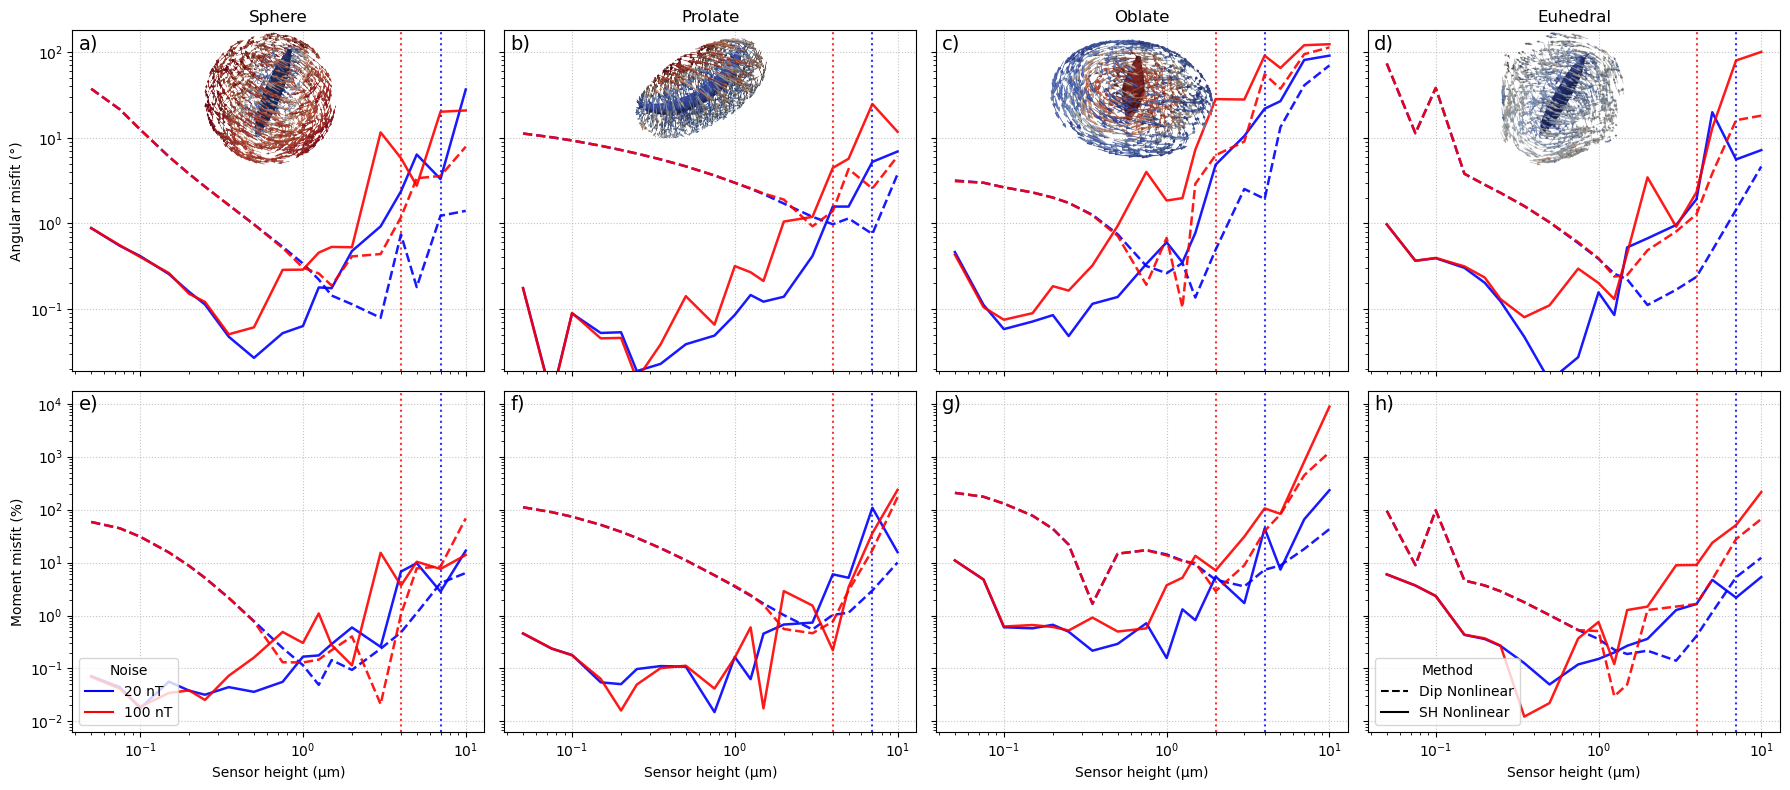

In [4]:
# =========================
# LOAD DATA
# =========================
dataframe_dir = pathlib.Path("../../data/noise_levels")
results_df = pd.read_csv(dataframe_dir / "misfit_results_noise_levels.csv")
figure_dir = pathlib.Path("../../paper/figures")

# =========================
# FILTER MODELS
# =========================
selected_models = ["eps2", "eps7", "eps12", "eps17"]
results_df = results_df[results_df["model"].isin(selected_models)]

# =========================
# NOISE LEVELS
# =========================
noise_levels = sorted(results_df["noise_nT"].unique())

color_map = {
    20: "blue",
    100: "red"
}

# =========================
# GEOMETRY
# =========================
geometry_data = {
    "model": [f"eps{i}" for i in range(20)],
    "shape": ["Sphere"] * 5 + ["Prolate"] * 5 + ["Oblate"] * 5 + ["Euhedral"] * 5,
}

geometry_df = pd.DataFrame(geometry_data)
results_df = results_df.merge(geometry_df, on="model")

# =========================
# MISFITS
# =========================
misfits = [
    ("angular_dipole_nonlinear", "angular_multipole_nonlinear", "Angular misfit (°)"),
    ("moment_misfit_dipole_nonlinear", "moment_misfit_multipole_nonlinear", "Moment misfit (%)"),
]

# =========================
# METHODS
# =========================
methods_to_plot = {
    "dipole": {
        "col": lambda cols: cols[0],
        "linestyle": "--"
    },
    "sph": {
        "col": lambda cols: cols[1],
        "linestyle": "-"
    }
}

# =========================
# PLOT
# =========================
shapes = ["Sphere", "Prolate", "Oblate", "Euhedral"]

fig, axes = plt.subplots(len(misfits), len(shapes),
                         figsize=(18, 8),
                         sharex=True, sharey='row')

for col_idx, shape in enumerate(shapes):
    subset_shape = results_df[results_df["shape"] == shape]

    for row_idx, (col_dip, col_sph, ylabel) in enumerate(misfits):
        ax = axes[row_idx, col_idx]

        for model in subset_shape["model"].unique():
            model_subset = subset_shape[subset_shape["model"] == model]

            for noise in [20, 100]:
                hcrit = critical_heights.get(model, {}).get(noise, None)
            
                if hcrit is not None:
                    ax.axvline(
                        hcrit,
                        color=color_map[noise],
                        linestyle=":",
                        linewidth=1.5,
                        alpha=0.8
                    )

            for noise in noise_levels:
                data_noise = model_subset[model_subset["noise_nT"] == noise]

                if data_noise.empty:
                    continue

                data_noise = data_noise.sort_values("height_um")

                # Dipole nonlinear
                ax.plot(
                    data_noise["height_um"],
                    data_noise[col_dip],
                    color=color_map[noise],
                    linestyle="--",
                    linewidth=1.8,
                    alpha=0.9,
                )

                # SH nonlinear
                ax.plot(
                    data_noise["height_um"],
                    data_noise[col_sph],
                    color=color_map[noise],
                    linestyle="-",
                    linewidth=1.8,
                    alpha=0.9,
                )

        # escalas
        ax.set_xscale("log")
        ax.set_yscale("log")
        ax.grid(ls=':', alpha=0.75)

        # linhas de referência
        if "Angular" in ylabel:
            # ax.axhline(10, color="gray", linestyle=":", linewidth=1)
            # ax.axhline(1, color="gray", linestyle="--", linewidth=1)
            ax.set_ylim(None, 180)
        # else:
        #     ax.axhline(10, color="gray", linestyle="--", linewidth=1)
        #     ax.axhline(1, color="gray", linestyle="--", linewidth=1)

        # labels
        if row_idx == len(misfits) - 1:
            ax.set_xlabel("Sensor height (µm)")
        if col_idx == 0:
            ax.set_ylabel(ylabel)
        if row_idx == 0:
            ax.set_title(shape)

# =========================
# LEGEND
# =========================

noise_handles = [
    mlines.Line2D([], [], color=color_map[n], linestyle='-', label=f"{n} nT")
    for n in noise_levels
]

method_handles = [
    mlines.Line2D([], [], color='black', linestyle='--', label="Dip Nonlinear"),
    mlines.Line2D([], [], color='black', linestyle='-', label="SH Nonlinear"),
]

axes[1, 0].legend(handles=noise_handles, title="Noise", loc="lower left")
axes[1, -1].legend(handles=method_handles, title="Method", loc="lower left")

for ax, letter in zip(axes.ravel(), "a b c d e f g h i j k l m".split()):
    ax.text(0.015, 0.945, f"{letter})", transform=ax.transAxes, fontsize=14)


# =========================
# Insets with grain models
# =========================

shape_image_map = {
    "Sphere": "eps2.png",
    "Prolate": "eps7.png",
    "Oblate": "eps12.png",
    "Euhedral": "eps17.png",
}

for col_idx, shape in enumerate(shapes):
    ax = axes[0, col_idx]

    img_path = image_dir / shape_image_map[shape]

    print("Loading:", img_path)  # 👈 DEBUG

    if img_path.exists():
        img = mpimg.imread(img_path)
        ax_inset = ax.inset_axes([0.275, 0.6, 0.4, 0.4])

        ax_inset.imshow(img)
        ax_inset.set_xticks([])
        ax_inset.set_yticks([])
        ax_inset.set_frame_on(False)
        
        ax_inset.patch.set_alpha(0) 
        ax_inset.set_facecolor("none")  
        
        for spine in ax_inset.spines.values():
            spine.set_visible(False)

    else:
        print("NOT FOUND:", img_path)



# =========================
# FINAL
# =========================
plt.tight_layout()

# plt.savefig(figure_dir / "noise_comparison_clean.png",
#             dpi=300, bbox_inches="tight", transparent=True)

plt.show()

## Add position misfit

Loading: ../../data/micromag_models/shapes_png/eps2.png
Loading: ../../data/micromag_models/shapes_png/eps7.png
Loading: ../../data/micromag_models/shapes_png/eps12.png
Loading: ../../data/micromag_models/shapes_png/eps17.png


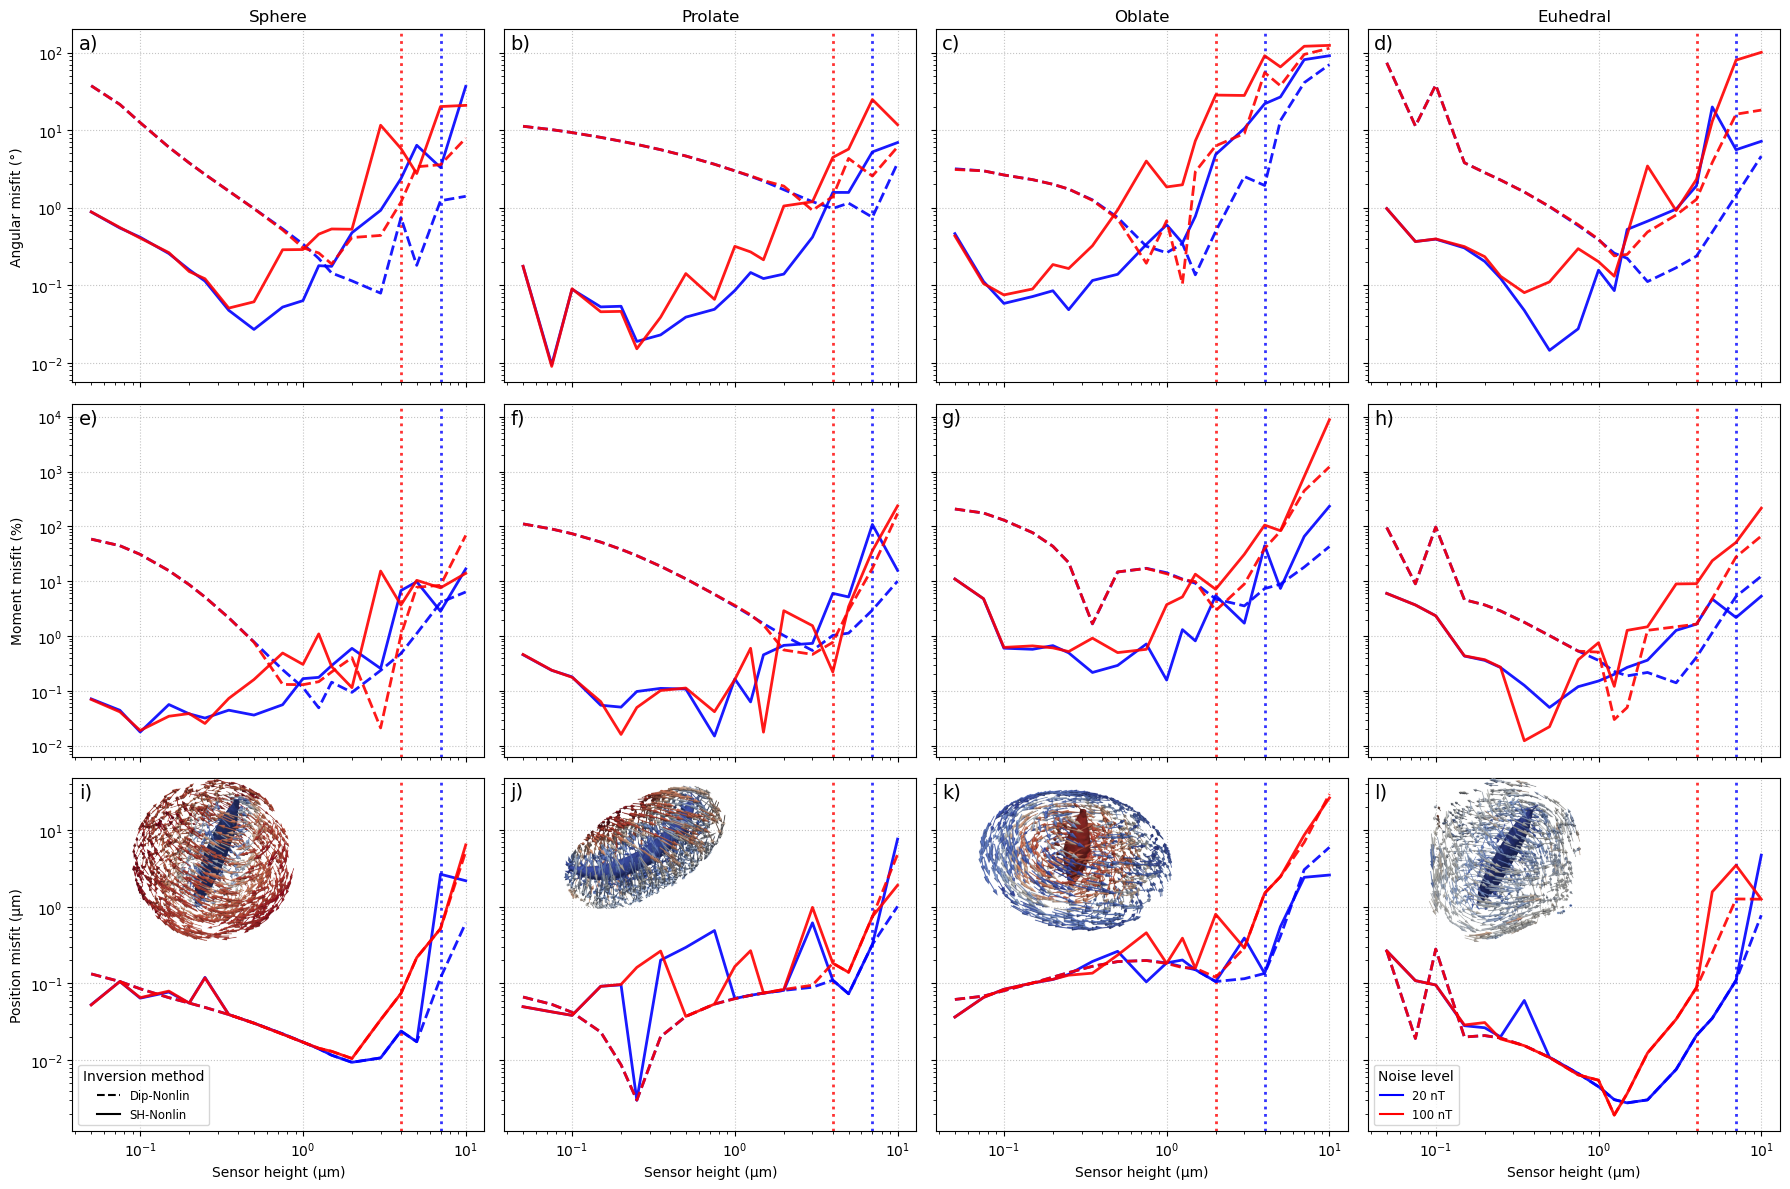

In [5]:
# =========================
# LOAD NOISY DATA RESULTS
# =========================

dataframe_dir = pathlib.Path("../../data/noise_levels")
results_df = pd.read_csv(dataframe_dir / "misfit_results_noise_levels.csv")
figure_dir = pathlib.Path("../../paper/figures")

# =========================
# Filter specific grains 
# =========================
selected_models = ["eps2", "eps7", "eps12", "eps17"]
results_df = results_df[results_df["model"].isin(selected_models)]

# =========================
# Geometry
# =========================
geometry_data = {
    "model": [f"eps{i}" for i in range(20)],
    "shape": ["Sphere"] * 5 + ["Prolate"] * 5 + ["Oblate"] * 5 + ["Euhedral"] * 5,
}

geometry_df = pd.DataFrame(geometry_data)
results_df = results_df.merge(geometry_df, on="model")

# =========================
# Noise Levels
# =========================
noise_levels = sorted(results_df["noise_nT"].unique())
noise_levels = [20, 100]
color_map = {
    20: "blue",
    100: "red"
}

# =========================
# Misfits
# =========================
misfits = [
    ("angular_dipole_nonlinear", "angular_multipole_nonlinear", "Angular misfit (°)"),
    ("moment_misfit_dipole_nonlinear", "moment_misfit_multipole_nonlinear", "Moment misfit (%)"),
    ("position_misfit_dipole_nonlinear", "position_misfit_multipole_nonlinear", "Position misfit (µm)"),
]

method_styles = {
    "dipole": {"linestyle": "--", "label": "Dipole Nonlinear"},
    "sph": {"linestyle": "-", "label": "SH Nonlinear"},
}

# =========================
# Plot
# =========================
shapes = ["Sphere", "Prolate", "Oblate", "Euhedral"]

fig, axes = plt.subplots(len(misfits), len(shapes),
                         figsize=(18, 12),
                         sharex=True, sharey='row')

for col_idx, shape in enumerate(shapes):
    subset_shape = results_df[results_df["shape"] == shape]

    for row_idx, (col_dip, col_sph, ylabel) in enumerate(misfits):
        ax = axes[row_idx, col_idx]

        for model in subset_shape["model"].unique():
            model_data = subset_shape[subset_shape["model"] == model]

            for noise in [20, 100]:
                hcrit = critical_heights.get(model, {}).get(noise, None)
            
                if hcrit is not None:
                    ax.axvline(
                        hcrit,
                        color=color_map[noise],
                        linestyle=":",
                        linewidth=2, #1.5,
                        alpha=0.8
                    )
            
            for noise in noise_levels:
                data_noise = model_data[model_data["noise_nT"] == noise]

                if data_noise.empty:
                    continue

                data_noise = data_noise.sort_values("height_um")

                # Dipole NL
                ax.plot(
                    data_noise["height_um"],
                    data_noise[col_dip],
                    color=color_map[noise],
                    linestyle=method_styles["dipole"]["linestyle"],
                    linewidth=2,
                    alpha=0.9,
                )

                # SH NL
                ax.plot(
                    data_noise["height_um"],
                    data_noise[col_sph],
                    color=color_map[noise],
                    linestyle=method_styles["sph"]["linestyle"],
                    linewidth=2,
                    alpha=0.9,
                )

        # escalas
        ax.set_xscale("log")
        ax.set_yscale("log")
        ax.grid(ls=':', alpha=0.75)


        # linhas guia
        # if "Position" in ylabel:
            # ax.axhline(1, color="gray", linestyle="--", linewidth=1)
            # ax.set_ylim(None, 1e1)
        # else:
        #     ax.axhline(10, color="gray", linestyle=":", linewidth=1)
        #     ax.axhline(1, color="gray", linestyle="--", linewidth=1)

        # labels
        if row_idx == len(misfits) - 1:
            ax.set_xlabel("Sensor height (µm)")
        if col_idx == 0:
            ax.set_ylabel(ylabel)
        if row_idx == 0:
            ax.set_title(shape)

# =========================
# LEGENDAS
# =========================

# Ruído (cores)
noise_handles = [
    mlines.Line2D([], [], color=color_map[n],
                  linestyle='-',
                  label=f"{n} nT")
    for n in noise_levels
]


method_handles = [
    mlines.Line2D([], [], color='black',
                  linestyle=method_styles["dipole"]["linestyle"],
                  label="Dip-Nonlin"),
    mlines.Line2D([], [], color='black',
                  linestyle=method_styles["sph"]["linestyle"],
                  label="SH-Nonlin"),
]


axes[-1, -1].legend(handles=noise_handles,
                   title="Noise level",
                   fontsize="small",
                   loc="lower left")

axes[-1, 0].legend(handles=method_handles,
                    title="Inversion method",
                    fontsize="small",
                    loc="lower left")


for ax, letter in zip(axes.ravel(), "a b c d e f g h i j k l m".split()):
    ax.text(0.015, 0.945, f"{letter})", transform=ax.transAxes, fontsize=14)

# for ax, letter in zip(axes.ravel()[-4:], "i' j' k' l'".split()):
#     ax.text(0.1, 0.55, f"{letter})", transform=ax.transAxes, fontsize=14)


# =========================
# Insets with grain models
# =========================

for col_idx, shape in enumerate(shapes):
    ax = axes[-1, col_idx]

    img_path = image_dir / shape_image_map[shape]

    print("Loading:", img_path)  # 👈 DEBUG

    if img_path.exists():
        img = mpimg.imread(img_path)

        ax_inset = ax.inset_axes([0.1, 0.53, 0.475, 0.475])

        ax_inset.imshow(img)
        ax_inset.set_xticks([])
        ax_inset.set_yticks([])
        ax_inset.set_frame_on(False)
        
        ax_inset.patch.set_alpha(0)  
        ax_inset.set_facecolor("none")    
        
        for spine in ax_inset.spines.values():
            spine.set_visible(False)

    else:
        print("NOT FOUND:", img_path)

# =========================
# FINAL
# =========================

plt.tight_layout()

plt.savefig(figure_dir / "model_comparison_noise_methods.png",
            dpi=300, bbox_inches="tight", transparent=True)

plt.show()

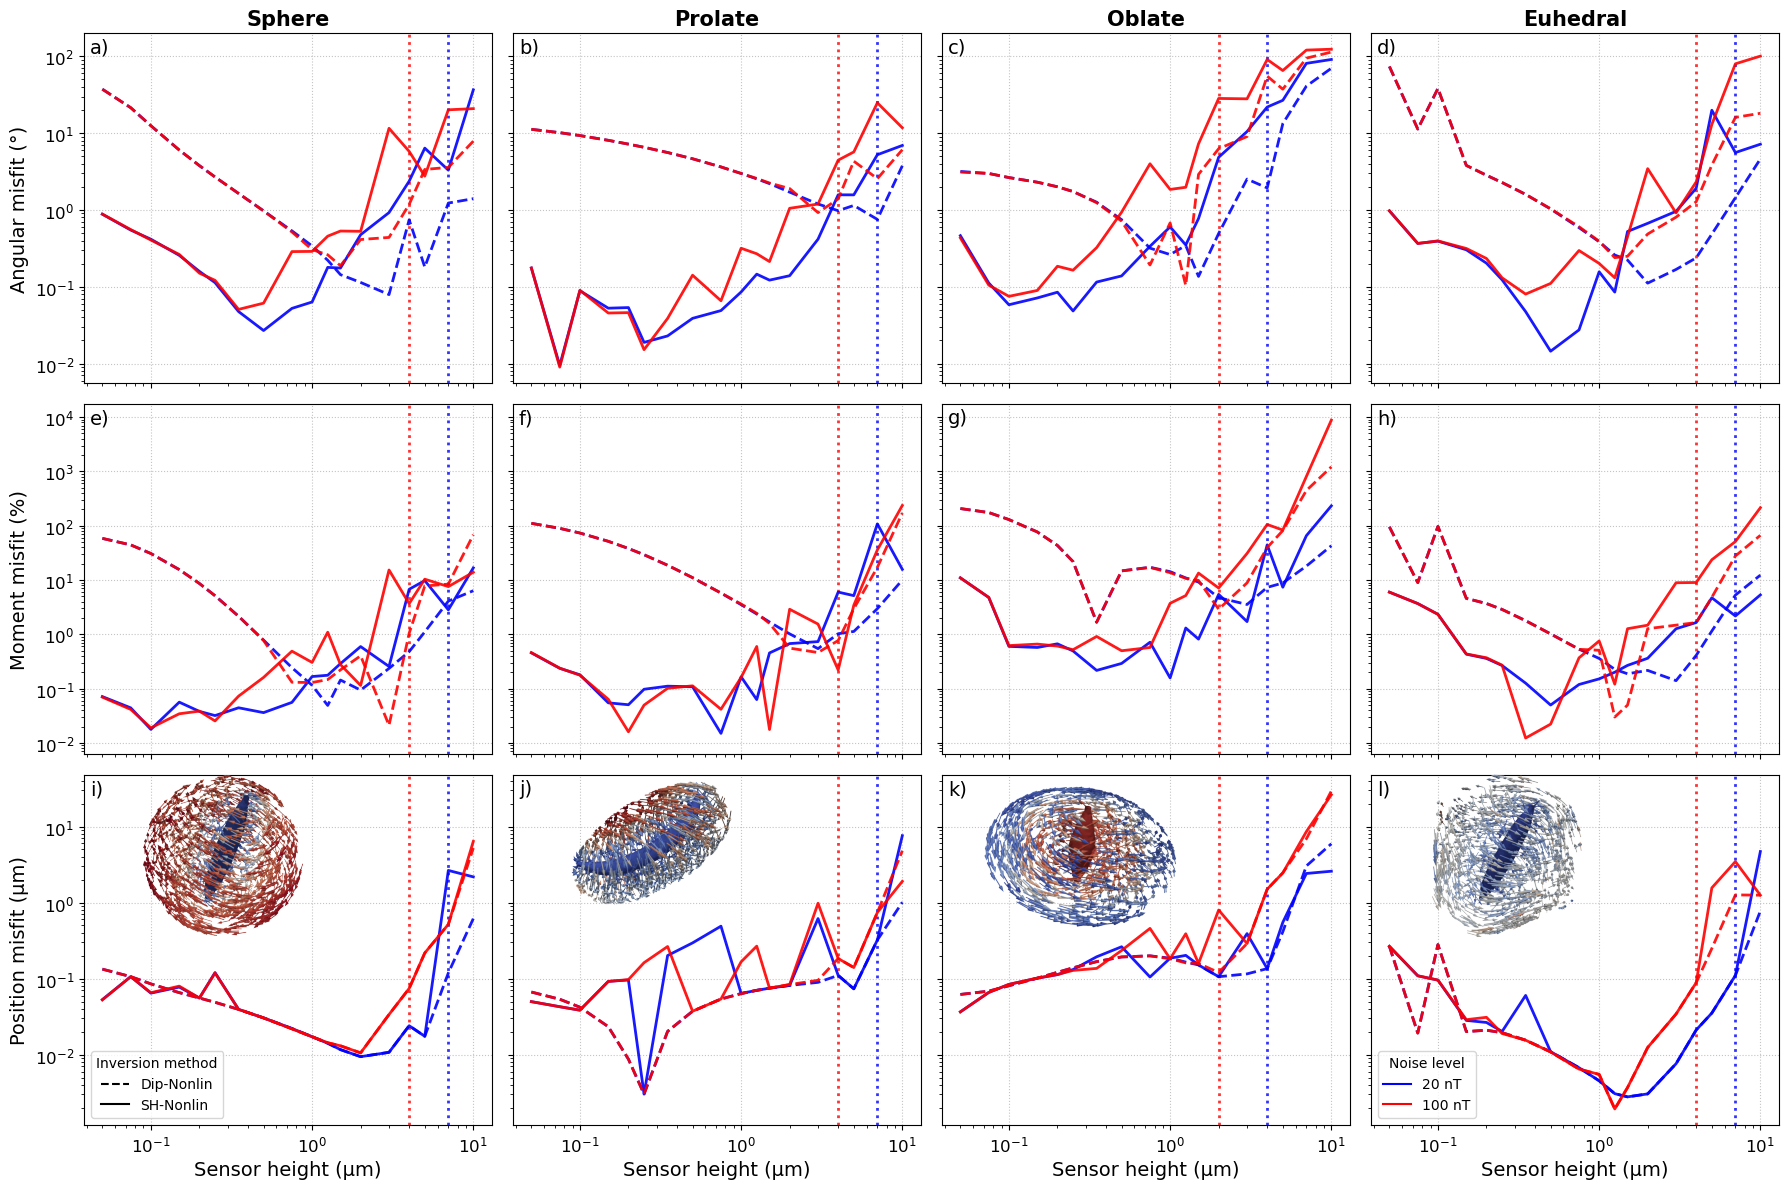

In [6]:
# LOAD NOISY DATA RESULTS

dataframe_dir = pathlib.Path("../../data/noise_levels")
results_df = pd.read_csv(dataframe_dir / "misfit_results_noise_levels.csv")
figure_dir = pathlib.Path("../../paper/figures")

# Filter specific grains 
selected_models = ["eps2", "eps7", "eps12", "eps17"]
results_df = results_df[results_df["model"].isin(selected_models)]

# Geometry
geometry_data = {
    "model": [f"eps{i}" for i in range(20)],
    "shape": ["Sphere"] * 5 + ["Prolate"] * 5 + ["Oblate"] * 5 + ["Euhedral"] * 5,
}

geometry_df = pd.DataFrame(geometry_data)
results_df = results_df.merge(geometry_df, on="model")

# Noise Levels
noise_levels = sorted(results_df["noise_nT"].unique())
noise_levels = [20, 100]
color_map = {
    20: "blue",
    100: "red"
}

# Misfits
misfits = [
    ("angular_dipole_nonlinear", "angular_multipole_nonlinear", "Angular misfit (°)"),
    ("moment_misfit_dipole_nonlinear", "moment_misfit_multipole_nonlinear", "Moment misfit (%)"),
    ("position_misfit_dipole_nonlinear", "position_misfit_multipole_nonlinear", "Position misfit (µm)"),
]

method_styles = {
    "dipole": {"linestyle": "--", "label": "Dipole Nonlinear"},
    "sph": {"linestyle": "-", "label": "SH Nonlinear"},
}

# Plot
shapes = ["Sphere", "Prolate", "Oblate", "Euhedral"]

fig, axes = plt.subplots(len(misfits), len(shapes),
                         figsize=(18, 12),
                         sharex=True, sharey='row')

for col_idx, shape in enumerate(shapes):
    subset_shape = results_df[results_df["shape"] == shape]

    for row_idx, (col_dip, col_sph, ylabel) in enumerate(misfits):
        ax = axes[row_idx, col_idx]

        for model in subset_shape["model"].unique():
            model_data = subset_shape[subset_shape["model"] == model]

            for noise in [20, 100]:
                hcrit = critical_heights.get(model, {}).get(noise, None)
            
                if hcrit is not None:
                    ax.axvline(
                        hcrit,
                        color=color_map[noise],
                        linestyle=":",
                        linewidth=2,
                        alpha=0.8
                    )
            
            for noise in noise_levels:
                data_noise = model_data[model_data["noise_nT"] == noise]

                if data_noise.empty:
                    continue

                data_noise = data_noise.sort_values("height_um")

                # Dipole NL
                ax.plot(
                    data_noise["height_um"],
                    data_noise[col_dip],
                    color=color_map[noise],
                    linestyle=method_styles["dipole"]["linestyle"],
                    linewidth=2,
                    alpha=0.9,
                )

                # SH NL
                ax.plot(
                    data_noise["height_um"],
                    data_noise[col_sph],
                    color=color_map[noise],
                    linestyle=method_styles["sph"]["linestyle"],
                    linewidth=2,
                    alpha=0.9,
                )

        # scales
        ax.set_xscale("log")
        ax.set_yscale("log")
        ax.grid(ls=':', alpha=0.75)

        ax.tick_params(axis='both', which='major', labelsize=12)

        if row_idx == len(misfits) - 1:
            ax.set_xlabel("Sensor height (µm)", fontsize=14)
        if col_idx == 0:
            ax.set_ylabel(ylabel, fontsize=14)
        if row_idx == 0:
            ax.set_title(shape, fontsize=15, fontweight='bold')

# Legends
noise_handles = [
    mlines.Line2D([], [], color=color_map[n],
                  linestyle='-',
                  label=f"{n} nT")
    for n in noise_levels
]

method_handles = [
    mlines.Line2D([], [], color='black',
                  linestyle=method_styles["dipole"]["linestyle"],
                  label="Dip-Nonlin"),
    mlines.Line2D([], [], color='black',
                  linestyle=method_styles["sph"]["linestyle"],
                  label="SH-Nonlin"),
]

axes[-1, -1].legend(handles=noise_handles,
                    title="Noise level",
                    fontsize=10,
                    loc="lower left")

axes[-1, 0].legend(handles=method_handles,
                   title="Inversion method",
                   fontsize=10,
                   loc="lower left")

for ax, letter in zip(axes.ravel(), "a b c d e f g h i j k l m".split()):
    ax.text(0.015, 0.945, f"{letter})", transform=ax.transAxes, fontsize=14)

# Insets with grain models
for col_idx, shape in enumerate(shapes):
    ax = axes[-1, col_idx]

    img_path = image_dir / shape_image_map[shape]

    if img_path.exists():
        img = mpimg.imread(img_path)

        ax_inset = ax.inset_axes([0.1, 0.53, 0.475, 0.475])

        ax_inset.imshow(img)
        ax_inset.set_xticks([])
        ax_inset.set_yticks([])
        ax_inset.set_frame_on(False)
        
        ax_inset.patch.set_alpha(0)  
        ax_inset.set_facecolor("none")     
        
        for spine in ax_inset.spines.values():
            spine.set_visible(False)


plt.tight_layout()

plt.savefig(figure_dir / "model_comparison_noise_methods.png",
            dpi=300, bbox_inches="tight", transparent=True)

plt.show()